# IoT Hardware Module — AI-Based Solar Power Generation Prediction System

**Capstone Project:** AI-Based Solar Power Generation Prediction System for India
**Team:** Aryan Sovit (2411021240074), Yashwanth Chandawat (2411021240005), Muhammed Faiz C K (2411021240042)

This notebook documents the **IoT hardware layer** of the project: *why* each sensor/device was chosen,
*how it physically works*, and *how it was integrated* into the edge-to-cloud data pipeline that
feeds the LSTM forecasting model described in the project presentation.

**Hardware used (from project architecture):**

| Component | Role |
|---|---|
| ESP32 Microcontroller | Edge device — reads all sensors, transmits data over Wi-Fi/MQTT |
| Irradiance Sensor (Pyranometer / Solar Irradiance Module) | Measures sunlight intensity (W/m²) hitting the panel |
| DS18B20 Digital Temperature Sensor | Measures panel surface temperature (°C) |
| INA219 Current/Power Sensor | Measures DC voltage, current, and power output of the panel |

This notebook is written so it can run **with or without the physical hardware connected**:
- If a **Serial/MQTT** connection to the ESP32 is available, live data is read.
- If not, a **physics-based simulator** generates realistic sensor data so the rest of the pipeline
  (storage → preprocessing → LSTM feature prep) can still be demonstrated end-to-end.


## 1. Why IoT Hardware Was Needed (Problem → Solution Mapping)

From the project's problem statement:

- **Blind weather forecasting**: public meteorological APIs report *macro-level* weather (city-wide),
  missing the **micro-climate** at the exact solar plant location — a passing cloud, local haze, or
  panel-level heating is invisible to a weather API.
- **Grid balancing failures**: without *ground-truth* generation data updated every minute, the AI model
  cannot correct itself when reality diverges from forecast.
- **Economic strain**: expensive fossil-fuel peaking plants are kept running "just in case" because
  operators don't trust forecasts that are not backed by real sensor telemetry.

**IoT hardware solves this by providing hyper-local, high-frequency, ground-truth telemetry** —
exactly the three physical quantities that determine instantaneous PV output:

1. **Irradiance** (the fuel — sunlight power hitting the panel)
2. **Temperature** (efficiency modifier — PV efficiency drops as panel gets hotter)
3. **Electrical output** (the ground truth — actual current/voltage/power being generated)

Together, these three signals let the LSTM model learn the *true* relationship between
weather conditions and generation, instead of relying only on coarse public weather data.


## 2. ESP32 Microcontroller — The Edge Device

### Why ESP32 was chosen
- **Built-in Wi-Fi** — no extra networking module needed to push data to MQTT/MySQL over the internet.
- **Multiple ADC + I2C + OneWire capable GPIO pins** — can talk to the irradiance sensor (analog),
  the INA219 (I2C), and the DS18B20 (OneWire) *simultaneously* from a single, cheap (~₹400) board.
- **Dual-core, low power draw** — can be solar-powered itself and left at the plant site continuously.
- **Large hobbyist/industrial ecosystem** — mature libraries for MQTT, HTTP, and sensor drivers,
  which reduces development time for a capstone timeline.

### How it works
The ESP32 runs a firmware loop (written in Arduino C++) that:
1. Reads all three sensors every fixed interval (project uses **1 minute**).
2. Packages the readings into a JSON payload with a timestamp.
3. Publishes the payload over Wi-Fi via **MQTT** (or a direct HTTP POST) to a broker/server,
   which writes it into the local **MySQL** database (Slide 5, "Edge Collection").

### Firmware logic (reference — runs on the ESP32, not in Python)
```cpp
// Pseudocode / Arduino sketch outline for the ESP32 edge node
#include <WiFi.h>
#include <PubSubClient.h>   // MQTT client
#include <OneWire.h>
#include <DallasTemperature.h>  // DS18B20 driver
#include <Adafruit_INA219.h>    // INA219 driver

OneWire oneWire(4);                     // DS18B20 data pin
DallasTemperature tempSensor(&oneWire);
Adafruit_INA219 ina219;                 // I2C current/power sensor
const int IRRADIANCE_PIN = 34;          // Analog pin for irradiance sensor

void setup() {
  WiFi.begin(SSID, PASSWORD);
  tempSensor.begin();
  ina219.begin();
  mqttClient.setServer(BROKER_IP, 1883);
}

void loop() {
  tempSensor.requestTemperatures();
  float panelTempC   = tempSensor.getTempCByIndex(0);
  float busVoltage_V = ina219.getBusVoltage_V();
  float current_mA   = ina219.getCurrent_mA();
  float power_mW      = busVoltage_V * (current_mA / 1000.0) * 1000.0;
  int   rawADC        = analogRead(IRRADIANCE_PIN);
  float irradiance_Wm2 = mapADCToIrradiance(rawADC); // sensor-specific calibration curve

  String payload = buildJsonPayload(millis(), irradiance_Wm2, panelTempC,
                                     busVoltage_V, current_mA, power_mW);
  mqttClient.publish("solar/telemetry", payload.c_str());

  delay(60000); // 1-minute sampling interval, matches Slide 5 pipeline
}
```

The Python side of this notebook (below) consumes the **output** of this firmware —
either live over MQTT/Serial, or from the MySQL table it populates.


In [1]:
# --- Common setup ---
import json
import time
import random
import math
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_WITH_LIVE_HARDWARE = False   # Set True if ESP32 is connected via Serial/MQTT
SAMPLE_INTERVAL_SEC = 60         # Matches the 1-minute ESP32 sampling rate (Slide 5)

print("Live hardware mode:", RUN_WITH_LIVE_HARDWARE)


Live hardware mode: False


## 3. Irradiance Sensor — Measuring the "Fuel" for Solar Generation

### Why this sensor was used
Solar power output is, to first order, **directly proportional to irradiance** (the amount of
solar power per unit area, in W/m², striking the panel). Without a direct irradiance measurement,
the AI model would have to *infer* sunlight intensity indirectly from generation itself — which is
circular and useless for *forecasting*. A dedicated irradiance sensor gives the model its most
important **leading indicator**.

### Working principle
- A **pyranometer / photodiode-based irradiance sensor** produces an output voltage or current
  proportional to the incident solar radiation.
- The ESP32's analog-to-digital converter (ADC) reads this analog voltage as a raw integer
  (0–4095 for the ESP32's 12-bit ADC).
- A **calibration curve** (usually linear, derived from the sensor's datasheet or a reference
  pyranometer) converts the raw ADC value into physical units of **W/m²**.
- Typical daytime range in India: 0 W/m² (night/heavy cloud) up to ~1000–1100 W/m² (clear noon sun).

### How it was used in the pipeline
The irradiance reading is captured every sampling cycle alongside temperature and power,
timestamped, and stored — it becomes the single strongest input feature for the LSTM model,
since generation tracks it almost instantaneously (with a small lag caused by panel thermal inertia).


In [2]:
def read_irradiance_raw_adc():
    """
    On real hardware: analogRead(IRRADIANCE_PIN) on the ESP32, sent over MQTT/Serial.
    Here: simulate a raw 12-bit ADC value following a daylight bell curve + cloud noise,
    so the rest of the pipeline can be demonstrated without physical hardware attached.
    """
    hour = datetime.now().hour + datetime.now().minute / 60
    # Simple daylight bell curve centered at solar noon (hour 13 for IST clear-sky peak)
    daylight = max(0, math.sin((hour - 6) / 12 * math.pi)) if 6 <= hour <= 18 else 0
    cloud_noise = random.uniform(0.7, 1.0)  # simulates passing clouds reducing irradiance
    raw_adc = int(daylight * cloud_noise * 4095)
    return raw_adc


def adc_to_irradiance(raw_adc, adc_max=4095, irradiance_max_wm2=1100):
    """
    Calibration curve: converts raw ADC counts -> W/m^2.
    In a real deployment this slope/offset comes from comparing sensor output
    against a reference pyranometer (a one-time calibration step).
    """
    return round((raw_adc / adc_max) * irradiance_max_wm2, 2)


sample_raw = read_irradiance_raw_adc()
sample_irradiance = adc_to_irradiance(sample_raw)
print(f"Raw ADC: {sample_raw}  ->  Irradiance: {sample_irradiance} W/m^2")


Raw ADC: 0  ->  Irradiance: 0.0 W/m^2


## 4. DS18B20 — Panel Surface Temperature Sensor

### Why this sensor was used
Photovoltaic panels **lose efficiency as they heat up** (typically ~0.4–0.5% efficiency loss per °C
above 25°C, per manufacturer datasheets). Two panels under *identical* irradiance can produce
*different* power if one is hotter. Without temperature data, the model cannot explain this
efficiency variance — it would treat identical-irradiance days as identical-output days, which is
wrong. The DS18B20 was chosen specifically because it is:
- **Digital** (no analog calibration drift, unlike a thermistor).
- **Waterproof-probe variants available** — can be mounted directly on the panel backsheet outdoors.
- **OneWire protocol** — many sensors can share a single GPIO pin, useful if the project scales to
  multiple panels later.

### Working principle
- DS18B20 contains an internal temperature-sensing element and ADC, and communicates digitally over
  the **1-Wire protocol** (a single data line + ground, using parasitic or external power).
- The ESP32 issues a "convert temperature" command; the sensor performs an internal ADC conversion
  (9–12 bit resolution, configurable) and returns the result as a signed 16-bit value representing
  °C directly — no external calibration curve is needed, unlike the analog irradiance sensor.

### How it was used
The panel temperature is logged in the same timestamped record as irradiance and power, and used as
a **correction feature** in the LSTM — allowing the network to learn the efficiency de-rating effect
of heat directly from data, rather than a hand-coded formula.


In [3]:
def read_panel_temperature_c(ambient_base=28.0, irradiance_wm2=0.0):
    """
    On real hardware: tempSensor.requestTemperatures(); tempSensor.getTempCByIndex(0)
    via the DallasTemperature library talking to the DS18B20 over OneWire.
    Here: simulate panel temp = ambient + heating proportional to irradiance
    (a simplified NOCT-style model), plus small sensor noise.
    """
    heating_from_sun = irradiance_wm2 * 0.03   # simplified heating coefficient
    noise = random.uniform(-0.3, 0.3)          # DS18B20 has +/-0.5C typical accuracy
    return round(ambient_base + heating_from_sun + noise, 2)


sample_panel_temp = read_panel_temperature_c(irradiance_wm2=sample_irradiance)
print(f"Panel surface temperature: {sample_panel_temp} deg C")


Panel surface temperature: 27.9 deg C


## 5. INA219 — Current, Voltage & Power Sensor (Ground Truth)

### Why this sensor was used
This is the **ground-truth label generator** for the whole system. Everything else (irradiance,
temperature) are *predictors*; the INA219 measures what the panel is **actually producing right now**
— the value the LSTM is ultimately trying to forecast ahead of time. It was chosen because it:
- Measures **both current and bus voltage** on a single I2C chip, so power (`P = V x I`) can be
  computed directly on-device without extra shunt-resistor math in firmware.
- **I2C interface** means it shares the same two wires as other I2C peripherals, keeping ESP32 wiring
  simple.
- High accuracy (16-bit ADC internally) and low cost, well suited for a student capstone budget.

### Working principle
- The INA219 sits **in series with the panel's output**, using a small precision **shunt resistor**.
- It measures the tiny voltage drop across the shunt resistor to calculate **current**, and
  separately measures the **bus voltage** at the load.
- Both measurements are read by the ESP32 over I2C as digital register values, then converted to
  physical units (mA, V) using the library's built-in calibration (based on the shunt resistor value).
- Power is derived as `Power (W) = Bus Voltage (V) x Current (A)`.

### How it was used
This is the **target variable (y)** for supervised training — the AI (LSTM) is trained to predict
this exact quantity, N steps into the future, using the irradiance and temperature sequences as
input features (x).


In [4]:
def read_ina219_power(irradiance_wm2=0.0, panel_temp_c=25.0, panel_rated_w=300, panel_area_m2=1.6):
    """
    On real hardware: ina219.getBusVoltage_V() and ina219.getCurrent_mA()
    via the Adafruit_INA219 I2C driver.
    Here: simulate DC output using a simplified PV power model:
      P = irradiance-driven power * temperature de-rating factor
    """
    # Simplified PV model: power scales with irradiance fraction of 1000 W/m^2 STC
    irradiance_fraction = irradiance_wm2 / 1000.0
    raw_power_w = panel_rated_w * irradiance_fraction

    # Temperature de-rating: ~0.45%/C above 25C reference (typical crystalline silicon coefficient)
    temp_derate = 1 - 0.0045 * max(0, panel_temp_c - 25)
    power_w = max(0.0, raw_power_w * temp_derate)

    # Back out plausible bus voltage / current for a 12V nominal panel setup
    bus_voltage_v = round(12.0 + random.uniform(-0.2, 0.2), 2) if power_w > 0 else round(random.uniform(11.5,11.9),2)
    current_a = round(power_w / bus_voltage_v, 3) if bus_voltage_v > 0 else 0.0

    return {
        "bus_voltage_v": bus_voltage_v,
        "current_a": current_a,
        "power_w": round(power_w, 2),
    }


sample_electrical = read_ina219_power(sample_irradiance, sample_panel_temp)
print(sample_electrical)


{'bus_voltage_v': 11.66, 'current_a': 0.0, 'power_w': 0.0}


## 6. Edge Collection: Combining All Sensors into One Telemetry Record

This mirrors **Phase 1 / Slide 5 ("Edge Collection")** of the project: the ESP32 reads all three
sensors together, timestamps them, and pushes one combined JSON record every sampling interval
towards the MySQL database.


In [5]:
def collect_telemetry_record():
    """
    Simulates exactly one ESP32 sampling cycle:
      1. Read irradiance sensor (ADC -> W/m^2)
      2. Read DS18B20 panel temperature
      3. Read INA219 electrical output
      4. Package into one timestamped JSON record (as the ESP32 firmware would)
    """
    raw_adc = read_irradiance_raw_adc()
    irradiance = adc_to_irradiance(raw_adc)
    panel_temp = read_panel_temperature_c(irradiance_wm2=irradiance)
    electrical = read_ina219_power(irradiance, panel_temp)

    record = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "irradiance_wm2": irradiance,
        "panel_temp_c": panel_temp,
        "bus_voltage_v": electrical["bus_voltage_v"],
        "current_a": electrical["current_a"],
        "power_w": electrical["power_w"],
    }
    return record


print(json.dumps(collect_telemetry_record(), indent=2))


{
  "timestamp": "2026-09-03T05:55:02",
  "irradiance_wm2": 0.0,
  "panel_temp_c": 28.2,
  "bus_voltage_v": 11.89,
  "current_a": 0.0,
  "power_w": 0.0
}


### 6.1 Reading Live Data (when the ESP32 is physically connected)

If the ESP32 is connected over USB Serial (or MQTT), swap the simulator above for one of these:


In [6]:
# --- OPTION A: Reading from ESP32 over USB Serial ---
# import serial
# ser = serial.Serial('COM5', 115200, timeout=2)   # adjust COM port / baud rate
# line = ser.readline().decode('utf-8').strip()
# record = json.loads(line)   # ESP32 firmware sends one JSON line per sample

# --- OPTION B: Reading from ESP32 over MQTT ---
# import paho.mqtt.client as mqtt
# def on_message(client, userdata, msg):
#     record = json.loads(msg.payload.decode())
#     store_to_mysql(record)
#
# client = mqtt.Client()
# client.connect("BROKER_IP", 1883)
# client.subscribe("solar/telemetry")
# client.on_message = on_message
# client.loop_forever()

print("Live-hardware code paths shown above are reference implementations (commented out).")


Live-hardware code paths shown above are reference implementations (commented out).


## 7. Storing Telemetry — MySQL (Slide 5, "Edge Collection")

Each record produced above is written into a local MySQL table so that the historical
sequence is available for the LSTM's sliding-window training later.


In [7]:
# --- Reference: writing a record to MySQL (requires a running MySQL server + mysql-connector-python) ---
# import mysql.connector
#
# def store_to_mysql(record):
#     conn = mysql.connector.connect(host="localhost", user="solar_user",
#                                     password="password", database="solar_telemetry")
#     cursor = conn.cursor()
#     cursor.execute(
#         """INSERT INTO telemetry
#            (timestamp, irradiance_wm2, panel_temp_c, bus_voltage_v, current_a, power_w)
#            VALUES (%s, %s, %s, %s, %s, %s)""",
#         (record["timestamp"], record["irradiance_wm2"], record["panel_temp_c"],
#          record["bus_voltage_v"], record["current_a"], record["power_w"])
#     )
#     conn.commit()
#     cursor.close()
#     conn.close()

# --- For this notebook (no live MySQL server assumed): keep records in-memory / CSV instead ---
def store_to_dataframe(record, df):
    return pd.concat([df, pd.DataFrame([record])], ignore_index=True)

telemetry_df = pd.DataFrame(columns=[
    "timestamp", "irradiance_wm2", "panel_temp_c", "bus_voltage_v", "current_a", "power_w"
])
print("In-memory telemetry table initialized.")
telemetry_df


In-memory telemetry table initialized.


,timestamp,irradiance_wm2,panel_temp_c,bus_voltage_v,current_a,power_w


## 8. Simulating a Full Day of IoT Telemetry

Since we don't have the physical ESP32 + sensors connected in this notebook environment,
we simulate a **full day of 1-minute samples** (the exact cadence from Slide 5) so the
downstream preprocessing and LSTM feature-prep steps can be demonstrated with realistic data.

> When real hardware is deployed, this cell is simply replaced by pulling the day's rows
> directly from the MySQL `telemetry` table — the rest of the notebook is unchanged.


In [8]:
def simulate_day(date_str="2026-01-15", interval_minutes=1):
    """Generates one full day of simulated ESP32 telemetry at the given sampling interval."""
    start = datetime.strptime(date_str, "%Y-%m-%d")
    records = []
    for minute in range(0, 24 * 60, interval_minutes):
        t = start + timedelta(minutes=minute)
        hour = t.hour + t.minute / 60

        # Daylight irradiance model (clear-sky bell curve, 6am-6pm) with cloud noise
        if 6 <= hour <= 18:
            base = max(0, math.sin((hour - 6) / 12 * math.pi))
            cloud_factor = random.uniform(0.6, 1.0) if random.random() < 0.3 else 1.0
            irradiance = round(base * cloud_factor * 1050, 2)
        else:
            irradiance = 0.0

        panel_temp = read_panel_temperature_c(ambient_base=24.0, irradiance_wm2=irradiance)
        electrical = read_ina219_power(irradiance, panel_temp)

        records.append({
            "timestamp": t,
            "irradiance_wm2": irradiance,
            "panel_temp_c": panel_temp,
            "bus_voltage_v": electrical["bus_voltage_v"],
            "current_a": electrical["current_a"],
            "power_w": electrical["power_w"],
        })
    return pd.DataFrame(records)


telemetry_df = simulate_day(interval_minutes=5)   # 5-min steps here just to keep the demo light
telemetry_df.head()


,timestamp,irradiance_wm2,panel_temp_c,bus_voltage_v,current_a,power_w
0,2026-01-15 00:00:00,0.0,23.92,11.54,0.0,0.0
1,2026-01-15 00:05:00,0.0,24.28,11.82,0.0,0.0
2,2026-01-15 00:10:00,0.0,24.12,11.55,0.0,0.0
3,2026-01-15 00:15:00,0.0,23.83,11.78,0.0,0.0
4,2026-01-15 00:20:00,0.0,24.03,11.80,0.0,0.0


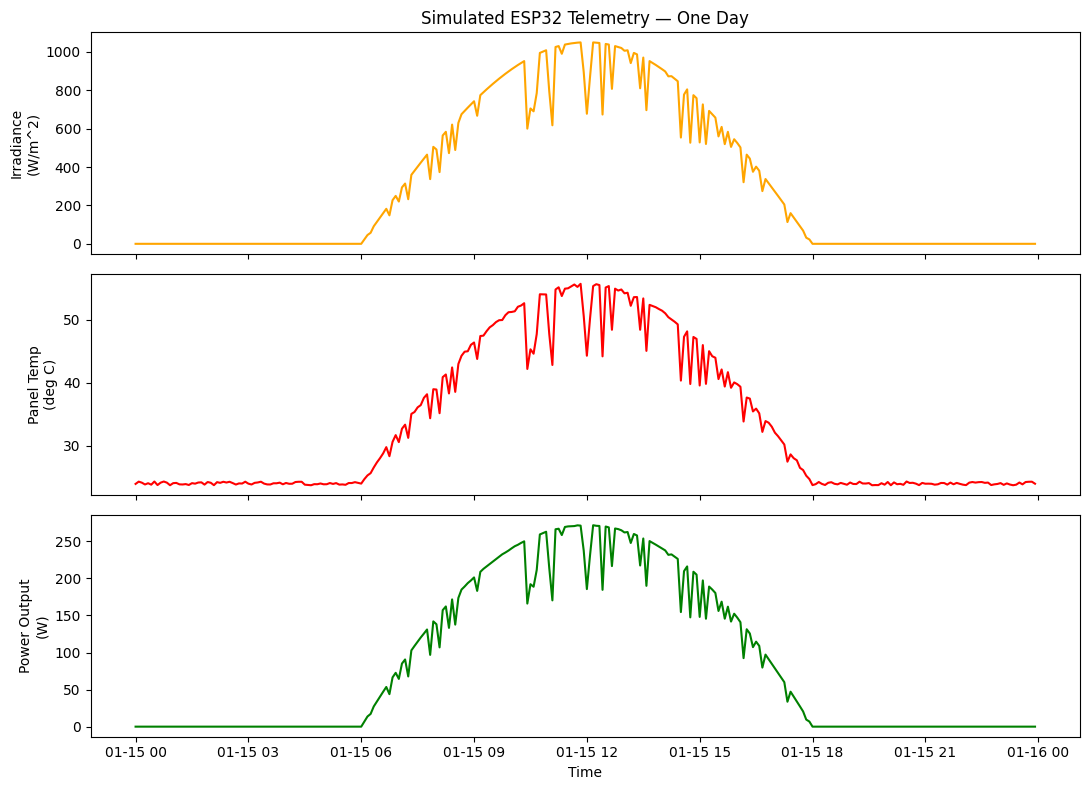

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(telemetry_df["timestamp"], telemetry_df["irradiance_wm2"], color="orange")
axes[0].set_ylabel("Irradiance\n(W/m^2)")
axes[0].set_title("Simulated ESP32 Telemetry — One Day")

axes[1].plot(telemetry_df["timestamp"], telemetry_df["panel_temp_c"], color="red")
axes[1].set_ylabel("Panel Temp\n(deg C)")

axes[2].plot(telemetry_df["timestamp"], telemetry_df["power_w"], color="green")
axes[2].set_ylabel("Power Output\n(W)")
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()


## 9. Data Processing (Slide 5, Step 2) — Preparing IoT Data for the LSTM

Per the project pipeline: *"Python script pulls database records, filters out night hours,
and scales historical sequence windows."* We reproduce that exact step here.


In [10]:
# 9.1 Filter out night hours (irradiance == 0 -> no generation, not useful for forecasting daytime yield)
daylight_df = telemetry_df[telemetry_df["irradiance_wm2"] > 0].reset_index(drop=True)
print(f"Full day samples: {len(telemetry_df)} -> Daylight-only samples: {len(daylight_df)}")

# 9.2 Scale features (Min-Max scaling, standard for LSTM inputs)
from sklearn.preprocessing import MinMaxScaler

feature_cols = ["irradiance_wm2", "panel_temp_c", "power_w"]
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(daylight_df[feature_cols])
scaled_df = pd.DataFrame(scaled_values, columns=[f"{c}_scaled" for c in feature_cols])
scaled_df.head()


Full day samples: 288 -> Daylight-only samples: 143


,irradiance_wm2_scaled,panel_temp_c_scaled,power_w_scaled
0,0.000000,0.000000,0.000000
1,0.022308,0.019020,0.025863
2,0.033652,0.030625,0.038926
3,0.066856,0.059639,0.076984
4,0.089076,0.085429,0.102167


In [11]:
# 9.3 Build sliding-window sequences for LSTM training
#     X = past N samples of (irradiance, panel_temp, power)
#     y = power_w at the next step (the value we're forecasting)

def make_sequences(data, window_size=12):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size, :])       # all 3 features, past `window_size` steps
        y.append(data[i + window_size, 2])          # power_w (index 2) at the next step
    return np.array(X), np.array(y)

WINDOW_SIZE = 12  # e.g. last 12 samples (1 hour of 5-min data) to predict the next reading
X, y = make_sequences(scaled_values, window_size=WINDOW_SIZE)
print("LSTM input shape (samples, timesteps, features):", X.shape)
print("LSTM target shape:", y.shape)


LSTM input shape (samples, timesteps, features): (131, 12, 3)
LSTM target shape: (131,)


## 10. Summary — Why Each Sensor Matters to the AI Model

| Sensor | Physical Quantity | Role in the AI Pipeline |
|---|---|---|
| Irradiance Sensor | Sunlight intensity (W/m²) | Primary predictive feature — near-instant correlation with output |
| DS18B20 | Panel surface temp (°C) | Corrective feature — explains efficiency loss under heat |
| INA219 | Voltage, Current, Power | Ground-truth **label** the LSTM is trained to forecast |
| ESP32 | — | Edge compute + Wi-Fi bridge tying all three sensors into one timestamped, database-ready record |

This hardware layer is what allows the AI model described in the rest of the capstone project to
move beyond generic weather-API forecasting and instead learn from **real, site-specific, minute-level
ground truth** — directly addressing the grid-instability problem the project sets out to solve.

**Next notebook in the pipeline:** LSTM model training and evaluation (RMSE / MAE) using the
`X`, `y` sequences prepared in Section 9, and comparison against public weather-API-only forecasts
(Slide 6).
